To learn building using code, lets start with some basic project here.

Lets build a **MLP (Multi Layer Perceptron)** also known as *Dense network* wired as *Feed Forward Network* to predict the number by passing a hand drawn digit image of dimensions 28 x 28.




In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

info related to passing data is clearly mentioned in the core_concepts.md file. go check out to understand some info about how and what type of data is passed in DL.

In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
X_test.shape


(10000, 28, 28)

In [5]:
#before scaling
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

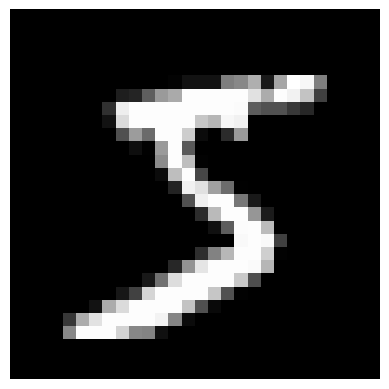

In [6]:
# This is an actual image from the database with the accesses off here and without the cmap variable there it would be displayed as heat map Colors
plt.imshow(X_train[0], cmap='gray')
plt.axis('off')

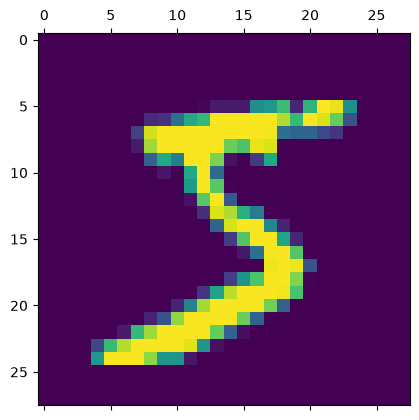

In [7]:
plt.matshow(X_train[0])

In [8]:
y_train[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

In [38]:
# scaling. we are scaling to see whether we can improve the accuracy, and it did increased that. once try it yourself, dont do this scaling and see how the model performs and use this again to see the change
X_train = X_train / 255
X_test = X_test / 255

In [ ]:
#after scaling 
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

now we got the data scaled, now the very first step of passing image to the network is flattening. which is discussed in the code_explanation.md file. 

In [11]:
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)

In [12]:
X_train_flattened.shape

(60000, 784)

In [ ]:
#after flattening 
X_train_flattened[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

x flattened values before scaling

```text
array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170, 253,
       253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253,
       253, 253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  18, 219, 253,
       253, 253, 253, 253, 198, 182, 247, 241,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        80, 156, 107, 253, 253, 205,  11,   0,  43, 154,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,  14,   1, 154, 253,  90,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0, 139, 253, 190,   2,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190, 253,  70,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
       241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,  81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,  45, 186, 253, 253, 150,  27,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,  16,  93, 252, 253, 187,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 249,
       253, 249,  64,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  46, 130,
       183, 253, 253, 207,   2,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39, 148,
       229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114,
       221, 253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  23,  66,
       213, 253, 253, 253, 253, 198,  81,   2,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  18, 171,
       219, 253, 253, 253, 253, 195,  80,   9,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  55, 172,
       226, 253, 253, 253, 253, 244, 133,  11,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
       136, 253, 253, 253, 212, 135, 132,  16,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0], dtype=uint8)
```

accuracy before scaling

```python
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),              
    layers.Dense(10, activation='sigmoid')   
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train_flattened, y_train, epochs=5)
```


```text
Epoch 1/5
[1m1875/1875[0m [32m━━━━━━━━━━━━━━━━━━━━[0m[37m[0m [1m2s[0m 726us/step - accuracy: 0.5051 - loss: 9.4911
Epoch 2/5
[1m1875/1875[0m [32m━━━━━━━━━━━━━━━━━━━━[0m[37m[0m [1m1s[0m 719us/step - accuracy: 0.4855 - loss: 6.0718
Epoch 3/5
[1m1875/1875[0m [32m━━━━━━━━━━━━━━━━━━━━[0m[37m[0m [1m1s[0m 711us/step - accuracy: 0.4644 - loss: 5.6409
Epoch 4/5
[1m1875/1875[0m [32m━━━━━━━━━━━━━━━━━━━━[0m[37m[0m [1m1s[0m 726us/step - accuracy: 0.4469 - loss: 5.4345
Epoch 5/5
[1m1875/1875[0m [32m━━━━━━━━━━━━━━━━━━━━[0m[37m[0m [1m1s[0m 713us/step - accuracy: 0.4358 - loss: 5.3963
```

In [ ]:
# training using flattened data
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),               # 1. Doorway: receives 784 inputs
    layers.Dense(10, activation='sigmoid')    # 3. Output layer: predicts 10 classes
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 728us/step - accuracy: 0.8786 - loss: 0.4651
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.9151 - loss: 0.3037
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 724us/step - accuracy: 0.9208 - loss: 0.2838
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 716us/step - accuracy: 0.9242 - loss: 0.2731
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 719us/step - accuracy: 0.9257 - loss: 0.2662


---

evaluation with one input and one output layer

In [25]:
model.evaluate(X_test_flattened, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 688us/step - accuracy: 0.9272 - loss: 0.2666


[0.26656574010849, 0.9272000193595886]

We can see that the accuracy is 92% here. without hidden layer

---


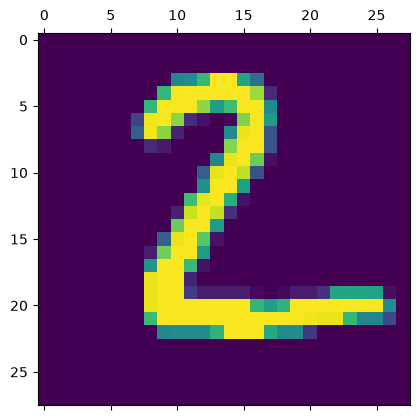

In [26]:
plt.matshow(X_test[1])

---

prediction part

In [27]:
y_predicted = model.predict(X_test_flattened)
y_predicted[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step


array([3.3221453e-01, 6.2359585e-03, 9.9900848e-01, 4.0196985e-01,
       4.0252934e-10, 8.1556833e-01, 8.5334855e-01, 8.2959350e-13,
       1.6075695e-01, 1.8032443e-09], dtype=float32)

In [28]:
np.max(y_predicted[1])

np.float32(0.9990085)

In [29]:
np.argmax(y_predicted[1])

np.int64(2)

y_predicted[1] is a 1D NumPy array of 10 float values (one for each class index $0$ through $9$):
```python
# Index:      0             1             2              3               4              5                6            7             8               9
array([5.2136672e-01, 8.1610456e-03, 9.9941289e-01, 3.6840507e-01, 7.7643597e-10, 8.4164476e-01, 9.4789755e-01, 1.3205790e-12, 2.5108370e-01, 5.4903753e-09], dtype=float32)
```

- np.max(...) would return the value 0.99.. (the highest score).
- np.argmax(...) returns the index (argument) where that maximum occurred. The maximum 0.9994129 is sitting at index 2.

If you are thinking if the value in the array is 9.99...  and here the np.max returned 0.99... you need to understand the math of `e-01`. which is related to exponents. just leave that because what we got is correct only.

In [30]:
y_predicted_labels = [np.argmax(i) for i in y_predicted]
y_predicted_labels[:5]

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4)]

In [31]:
y_test[:5]

array([7, 2, 1, 0, 4], dtype=uint8)

prediction part ends here

---

confusion matrix part starts here


In [32]:
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 961,    0,    3,    2,    0,    5,    5,    2,    2,    0],
       [   0, 1110,    3,    2,    0,    1,    4,    2,   13,    0],
       [   4,    9,  930,   18,    7,    4,   11,    8,   37,    4],
       [   2,    0,   21,  924,    0,   20,    2,   10,   22,    9],
       [   1,    1,    3,    2,  915,    0,   12,    4,   10,   34],
       [   9,    2,    4,   36,    9,  771,   13,    6,   35,    7],
       [  10,    3,    6,    1,    7,   12,  915,    2,    2,    0],
       [   1,    6,   27,    4,    9,    1,    0,  939,    2,   39],
       [   7,    7,    8,   17,    9,   23,    9,   10,  876,    8],
       [  10,    5,    2,    9,   25,    7,    0,   13,    7,  931]],
      dtype=int32)>

Text(95.83333333333333, 0.5, 'truth')

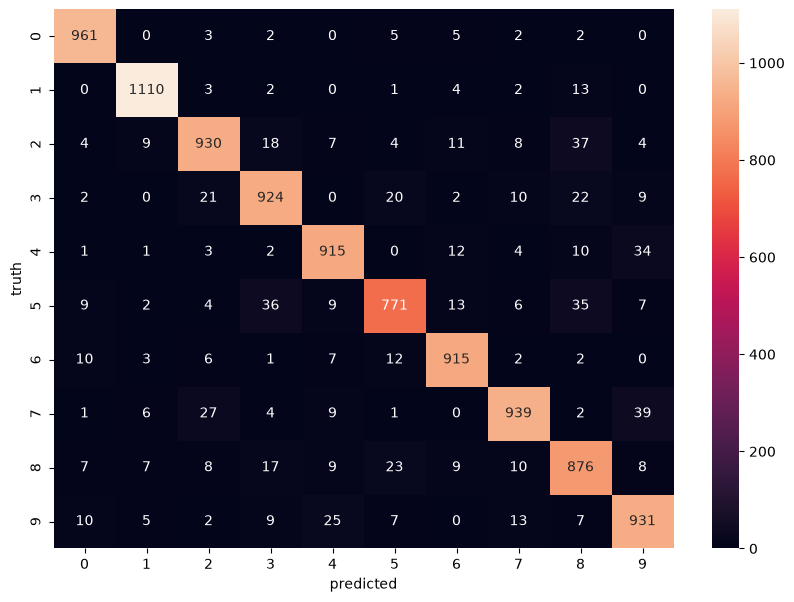

In [33]:
import seaborn as sn
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('predicted')
plt.ylabel('truth')

if you can understand the confusion matrix, we can see that there are lot of errors here related to misclassification. now remember this

---


now lets add a hidden layer and see how the model performs

In [34]:
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),               # 1. Doorway: receives 784 inputs
    layers.Dense(100, activation='relu'),     # 2. Hidden layer: 100 neurons
    layers.Dense(10, activation='sigmoid')    # 3. Output layer: predicts 10 classes
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train_flattened, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9228 - loss: 0.2711
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9644 - loss: 0.1224
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9745 - loss: 0.0861
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9810 - loss: 0.0641
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 982us/step - accuracy: 0.9840 - loss: 0.0515


---

evaluation part


In [36]:
model.evaluate(X_test_flattened, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step - accuracy: 0.9766 - loss: 0.0778


[0.07781503349542618, 0.9765999913215637]

Now see here, after adding hidden layer we got the accuracy increased from 92 to 97%

---


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 696us/step


Text(95.83333333333333, 0.5, 'truth')

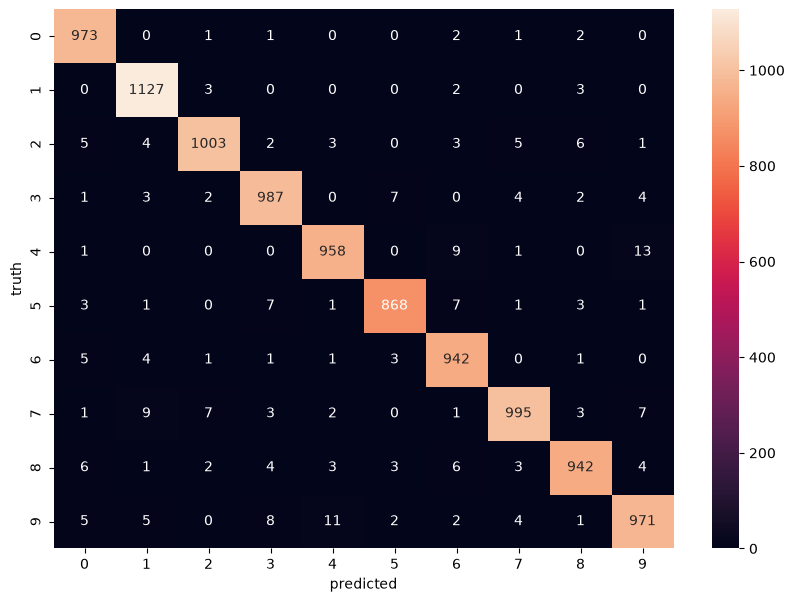

In [37]:
y_predicted = model.predict(X_test_flattened)
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_predicted_labels)

import seaborn as sn
plt.figure(figsize=(10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('predicted')
plt.ylabel('truth')

see this confusion matrix, you can see that the errors decreased compared to the older confusion matrix, go check the above one and see the changes.

---

now instead of we individually writing the flattening code, keras has inbuilt way to do that without we doing the code and it looks something like this

In [ ]:
import keras
from keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),               # 1. Doorway: receives 784 inputs
    layers.Flatten(),
    layers.Dense(100, activation='relu'),     # 2. Hidden layer: 100 neurons
    layers.Dense(10, activation='sigmoid')    # 3. Output layer: predicts 10 classes
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5)